In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth

## ĐỌC FILE TỪ THÀNH VIÊN 1
url = "https://raw.githubusercontent.com/KhoaDuong69/Data_Mining_Project/main/Data_Mining_Project/THKTDL/Data/food_association_ready.csv"
df_encoded = pd.read_csv(url)

print("Số sinh viên (transactions):", len(df_encoded))
print("Số item:", len(df_encoded.columns))
display(df_encoded.head())

Số sinh viên (transactions): 125
Số item: 37


,breakfast_Breakfast_No,breakfast_Breakfast_Yes,eating_out_High,eating_out_Low,eating_out_Medium,fruit_day_High,fruit_day_Low,fruit_day_Medium,veggies_day_High,veggies_day_Low,...,greek_food_Medium,indian_food_High,indian_food_Low,indian_food_Medium,thai_food_High,thai_food_Low,thai_food_Medium,ethnic_food_High,ethnic_food_Low,ethnic_food_Medium
0,1,0,0,0,1,1,0,0,1,0,...,0,1,0,0,0,1,0,0,1,0
1,1,0,0,1,0,0,0,1,0,0,...,1,0,0,1,0,1,0,0,0,1
2,1,0,0,1,0,1,0,0,1,0,...,0,1,0,0,1,0,0,1,0,0
3,1,0,0,1,0,0,0,1,0,0,...,0,1,0,0,1,0,0,1,0,0
4,1,0,0,1,0,0,0,1,0,0,...,1,0,1,0,0,0,1,0,0,1


 Kiểm tra dữ liệu đầu vào

 Kiểm tra giá trị thiếu, giá trị ngoài 0/1, tên cột trùng; sau đó đổi 0/1 thành False/True.

 astype(bool) có thể biến giá trị khác 0 (hoặc NaN) thành True, nên **phải kiểm tra trước khi chuyển kiểu**.

 Tránh kết quả support sai do dữ liệu lỗi. Không tự xóa các dòng khảo sát giống nhau: hai sinh viên trả lời giống nhau vẫn là hai transaction hợp lệ.

In [ ]:
# Kiểm tra dữ liệu trước khi chạy Apriori

print("Số ô bị thiếu:", df_encoded.isna().sum().sum())
print("Các giá trị xuất hiện:", pd.unique(df_encoded.to_numpy().ravel()))

if df_encoded.empty:
    print("Lỗi: File không có dữ liệu!")

elif df_encoded.columns.duplicated().any():
    print("Lỗi: Tên cột bị trùng!")

elif df_encoded.isna().sum().sum() > 0:
    print("Lỗi: Dữ liệu có giá trị thiếu!")

elif not df_encoded.isin([0, 1]).all().all():
    print("Lỗi: Dữ liệu phải chỉ chứa 0 và 1!")

else:
    print("Dữ liệu hợp lệ!")

    df_encoded = df_encoded.astype(bool)

    display(df_encoded.head())

Số ô bị thiếu: 0
Các giá trị xuất hiện: [1 0]
Dữ liệu hợp lệ!


,breakfast_Breakfast_No,breakfast_Breakfast_Yes,eating_out_High,eating_out_Low,eating_out_Medium,fruit_day_High,fruit_day_Low,fruit_day_Medium,veggies_day_High,veggies_day_Low,...,greek_food_Medium,indian_food_High,indian_food_Low,indian_food_Medium,thai_food_High,thai_food_Low,thai_food_Medium,ethnic_food_High,ethnic_food_Low,ethnic_food_Medium
0,True,False,False,False,True,True,False,False,True,False,...,False,True,False,False,False,True,False,False,True,False
1,True,False,False,True,False,False,False,True,False,False,...,True,False,False,True,False,True,False,False,False,True
2,True,False,False,True,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,False
3,True,False,False,True,False,False,False,True,False,False,...,False,True,False,False,True,False,False,True,False,False
4,True,False,False,True,False,False,False,True,False,False,...,True,False,True,False,False,False,True,False,False,True


THUẬT TOÁN APRIORI MINSUP=0.1

 Tìm các tập item xuất hiện trong ít nhất 10% số sinh viên. use_colnames=True hiển thị tên thuộc tính thay cho mã cột.

 Nếu một tập item không phổ biến thì mọi tập chứa nó cũng không phổ biến. Nhờ vậy thuật toán loại bớt các ứng viên.

Tìm các thói quen hoặc sở thích thường xuất hiện cùng nhau và tạo đầu vào cho phần sinh luật của Thành viên 3.

Thời gian được đo bằng time.perf_counter() đặt ngay trước và sau lời gọi thuật toán.

In [ ]:
from mlxtend.frequent_patterns import apriori

start_time = time.perf_counter()

frequent_itemsets_ap = apriori(
    df_encoded,
    min_support=0.1,
    use_colnames=True
)

apriori_time = time.perf_counter() - start_time

print("KẾT QUẢ Thuật Toán")
print("Min Support:", 0.1)
print("Số frequent itemsets:", len(frequent_itemsets_ap))
print("Thời gian chạy:", round(apriori_time, 6), "giây")

display(frequent_itemsets_ap)

KẾT QUẢ Thuật Toán
Min Support: 0.1
Số frequent itemsets: 2558
Thời gian chạy: 0.049266 giây


,support,itemsets
0,0.888,(breakfast_Breakfast_No)
1,0.112,(breakfast_Breakfast_Yes)
2,0.608,(eating_out_Low)
3,0.296,(eating_out_Medium)
4,0.504,(fruit_day_High)
...,...,...
2553,0.112,"(ethnic_food_High, thai_food_High, fruit_day_H..."
2554,0.112,"(healthy_feeling_High, ethnic_food_High, thai_..."
2555,0.120,"(eating_out_Low, ethnic_food_High, thai_food_H..."
2556,0.112,"(ethnic_food_High, thai_food_High, fruit_day_H..."


Thuật toán FP-Growth cùng MinSup sử dụng cùng minsup=0.1

In [ ]:
minsup = 0.1
start = time.perf_counter()
frequent_itemsets_fp = fpgrowth(df_encoded, min_support=minsup, use_colnames=True)
fpgrowth_time = time.perf_counter() - start

print("FP-Growth - số tập phổ biến:", len(frequent_itemsets_fp))
print("Thời gian (giây):", round(fpgrowth_time, 6))
display(frequent_itemsets_fp.sort_values("support", ascending=False).head(20))

FP-Growth - số tập phổ biến: 2558
Thời gian (giây): 1.286363


,support,itemsets
0,0.888,(breakfast_Breakfast_No)
1,0.800,(italian_food_High)
34,0.720,"(italian_food_High, breakfast_Breakfast_No)"
12,0.616,(healthy_feeling_High)
13,0.608,(eating_out_Low)
807,0.560,"(healthy_feeling_High, breakfast_Breakfast_No)"
810,0.536,"(eating_out_Low, breakfast_Breakfast_No)"
14,0.536,(cook_Medium)
15,0.504,(nutritional_check_Medium)
16,0.504,(calories_day_Medium)


THUẬT TOÁN IT _TREE CHO NGƯỠNG MINSUP=0.1

In [ ]:
def it_tree_mining(df, minsup=0.1):
    n = len(df)
    if n == 0:
        raise ValueError("Dữ liệu rỗng")
    if not 0 < minsup <= 1:
        raise ValueError("MinSup phải nằm trong khoảng (0, 1]")

    # Lấy các giao dịch chứa từng item
    items = [
        (col, set(df.index[df[col]]))
        for col in df.columns
    ]

    results = []

    # Tìm các tập phổ biến bằng cách giao TID
    def search(prefix, items):
        for i, (name, tids) in enumerate(items):
            if len(tids) / n < minsup:
                continue

            new_set = prefix | {name}
            results.append((len(tids) / n, frozenset(new_set)))

            next_items = [
                (name2, tids & tids2)
                for name2, tids2 in items[i + 1:]
            ]

            search(new_set, next_items)

    search(set(), items)

    return pd.DataFrame(results, columns=["support", "itemsets"])


# RUN IT-Tree
start = time.perf_counter()

frequent_itemsets_it = it_tree_mining(df_encoded, 0.1)

it_time = time.perf_counter() - start

print("Số tập phổ biến:", len(frequent_itemsets_it))
print("Thời gian:", round(it_time, 6), "giây")

display(frequent_itemsets_it.head(20))

Số tập phổ biến: 2558
Thời gian: 0.032984 giây


,support,itemsets
0,0.888,(breakfast_Breakfast_No)
1,0.536,"(eating_out_Low, breakfast_Breakfast_No)"
2,0.288,"(eating_out_Low, fruit_day_High, breakfast_Bre..."
3,0.216,"(veggies_day_High, eating_out_Low, fruit_day_H..."
4,0.136,"(eating_out_Low, veggies_day_High, calories_da..."
5,0.120,"(eating_out_Low, veggies_day_High, calories_da..."
6,0.112,"(eating_out_Low, veggies_day_High, cook_Medium..."
7,0.128,"(eating_out_Low, healthy_feeling_High, veggies..."
8,0.104,"(eating_out_Low, healthy_feeling_High, veggies..."
9,0.104,"(nutritional_check_Medium, eating_out_Low, veg..."


KIỂM TRA 3 THUẬT TOÁN

In [ ]:
# KIỂM TRA KẾT QUẢ 3 THUẬT TOÁN

# Lấy các tập phổ biến
ap = set(frequent_itemsets_ap["itemsets"])
fp = set(frequent_itemsets_fp["itemsets"])
it = set(frequent_itemsets_it["itemsets"])

# In số lượng tập phổ biến
print("Apriori:", len(ap))
print("FP-Growth:", len(fp))
print("IT-Tree:", len(it))

# So sánh kết quả
if ap == fp == it:
    print("3 thuật toán cho cùng tập phổ biến")
else:
    print("3 thuật toán cho kết quả khác nhau")

Apriori: 2558
FP-Growth: 2558
IT-Tree: 2558
3 thuật toán cho cùng tập phổ biến


##CÁC TẬP PHỔ BIẾN CÓ SUPPORT CAO NHẤT Ở 3 THUẬT TOÁN

In [ ]:
# HÀM KHAI PHÁ TẬP PHỔ BIẾN
def mine_itemsets(minsup):
    # Chạy Apriori với ngưỡng MinSup
    frequent_itemsets = apriori(
        df_encoded,
        min_support=minsup,
        use_colnames=True
    )
    return frequent_itemsets

# TOP 10 TẬP PHỔ BIẾN CÓ SUPPORT CAO NHẤT

# Khai phá tập phổ biến
frequent_itemsets = mine_itemsets(0.1)

# Sắp xếp Support từ cao xuống thấp
top10 = frequent_itemsets.sort_values(
    "support", ascending=False
).head(10).copy()

# Chuyển tập mục thành chuỗi
top10["Tập phổ biến"] = top10["itemsets"].apply(
    lambda x: ", ".join(sorted(x))
)

# Số mục trong mỗi tập
top10["Số mục"] = top10["itemsets"].apply(len)

# Đếm chính xác số sinh viên có đủ các đặc điểm
top10["Số sinh viên"] = top10["itemsets"].apply(
    lambda items: int(df_encoded[list(items)].all(axis=1).sum())
)

# Bảng kết quả
bang_top10 = top10[
    ["Tập phổ biến", "Số mục", "support", "Số sinh viên"]
].rename(columns={"support": "Support"})

print("TOP 10 TẬP PHỔ BIẾN CÓ SUPPORT CAO NHẤT")
display(bang_top10.round(3))


# TOP 10 TẬP PHỔ BIẾN CÓ TỪ 2 MỤC TRỞ LÊN

top10_ket_hop = frequent_itemsets[
    frequent_itemsets["itemsets"].apply(len) >= 2
].sort_values("support", ascending=False).head(10).copy()

top10_ket_hop["Tập phổ biến"] = top10_ket_hop["itemsets"].apply(
    lambda x: ", ".join(sorted(x))
)

top10_ket_hop["Số mục"] = top10_ket_hop["itemsets"].apply(len)

top10_ket_hop["Số sinh viên"] = top10_ket_hop["itemsets"].apply(
    lambda items: int(df_encoded[list(items)].all(axis=1).sum())
)

bang_ket_hop = top10_ket_hop[
    ["Tập phổ biến", "Số mục", "support", "Số sinh viên"]
].rename(columns={"support": "Support"})

print("TOP 10 TẬP PHỔ BIẾN CÓ TỪ 2 ITEM TRỞ LÊN")
display(bang_ket_hop.round(3))

TOP 10 TẬP PHỔ BIẾN CÓ SUPPORT CAO NHẤT


,Tập phổ biến,Số mục,Support,Số sinh viên
0,breakfast_Breakfast_No,1,0.888,111
20,italian_food_High,1,0.800,100
51,"breakfast_Breakfast_No, italian_food_High",2,0.720,90
14,healthy_feeling_High,1,0.616,77
2,eating_out_Low,1,0.608,76
45,"breakfast_Breakfast_No, healthy_feeling_High",2,0.560,70
13,cook_Medium,1,0.536,67
34,"breakfast_Breakfast_No, eating_out_Low",2,0.536,67
19,nutritional_check_Medium,1,0.504,63
10,calories_day_Medium,1,0.504,63


TOP 10 TẬP PHỔ BIẾN CÓ TỪ 2 ITEM TRỞ LÊN


,Tập phổ biến,Số mục,Support,Số sinh viên
51,"breakfast_Breakfast_No, italian_food_High",2,0.720,90
45,"breakfast_Breakfast_No, healthy_feeling_High",2,0.560,70
34,"breakfast_Breakfast_No, eating_out_Low",2,0.536,67
36,"breakfast_Breakfast_No, fruit_day_High",2,0.488,61
44,"breakfast_Breakfast_No, cook_Medium",2,0.480,60
76,"eating_out_Low, italian_food_High",2,0.472,59
237,"healthy_feeling_High, italian_food_High",2,0.472,59
41,"breakfast_Breakfast_No, calories_day_Medium",2,0.464,58
50,"breakfast_Breakfast_No, nutritional_check_Medium",2,0.456,57
64,"breakfast_Breakfast_No, ethnic_food_Medium",2,0.448,56


##Thực nghiệm Trục B: MinSup và thời gian chạy
 Với các mức MinSup 5%, 10%, 15%, 20%, 25%, 30%; lưu số tập phổ biến và thời gian.

MinSup thấp thường giữ nhiều tập phổ biến hơn.

Đo thời gian ở nhiều ngưỡng cho thấy thuật toán phản ứng thế nào khi độ khó thay đổi.

Có bảng và biểu đồ đúng yêu cầu Trục B. Mỗi cấu hình được chạy 3 lần và lấy trung vị để hạn chế dao động thời gian trên Colab;

Đồng thời do dữ liệu nhỏ nên thời gian có thể rất ngắn và không ổn định sau mỗi lần chạy.

In [ ]:
# THỰC NGHIỆM MINSUP VÀ THỜI GIAN CHẠY

minsup_values = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
results = []

for ms in minsup_values:

    # Apriori
    time_ap = []
    for i in range(3):
        start = time.perf_counter()
        ap = apriori(df_encoded, min_support=ms, use_colnames=True)
        time_ap.append(time.perf_counter() - start)

    # FP-Growth
    time_fp = []
    for i in range(3):
        start = time.perf_counter()
        fp = fpgrowth(df_encoded, min_support=ms, use_colnames=True)
        time_fp.append(time.perf_counter() - start)

    # IT-Tree
    time_it = []
    for i in range(3):
        start = time.perf_counter()
        it = it_tree_mining(df_encoded, ms)
        time_it.append(time.perf_counter() - start)

    # Lưu kết quả
    results.append({
        "MinSup": ms,
        "Apriori_Time": sorted(time_ap)[1],
        "FP_Growth_Time": sorted(time_fp)[1],
        "IT_Tree_Time": sorted(time_it)[1],
        "Apriori_Itemsets": len(ap),
        "FP_Growth_Itemsets": len(fp),
        "IT_Tree_Itemsets": len(it)
    })

experiment_df = pd.DataFrame(results)

display(experiment_df)

,MinSup,Apriori_Time,FP_Growth_Time,IT_Tree_Time,Apriori_Itemsets,FP_Growth_Itemsets,IT_Tree_Itemsets
0,0.05,0.211421,6.157779,0.079262,11618,11618,11618
1,0.10,0.047862,2.242241,0.026067,2558,2558,2558
2,0.15,0.017895,0.428138,0.014808,873,873,873
3,0.20,0.009349,0.183493,0.009238,373,373,373
4,0.25,0.005824,0.071380,0.005974,156,156,156
5,0.30,0.005079,0.041152,0.004855,90,90,90


BIỂU ĐỒ THỰC NGHIỆM


Biểu đồ MinSup và số tập phổ biến

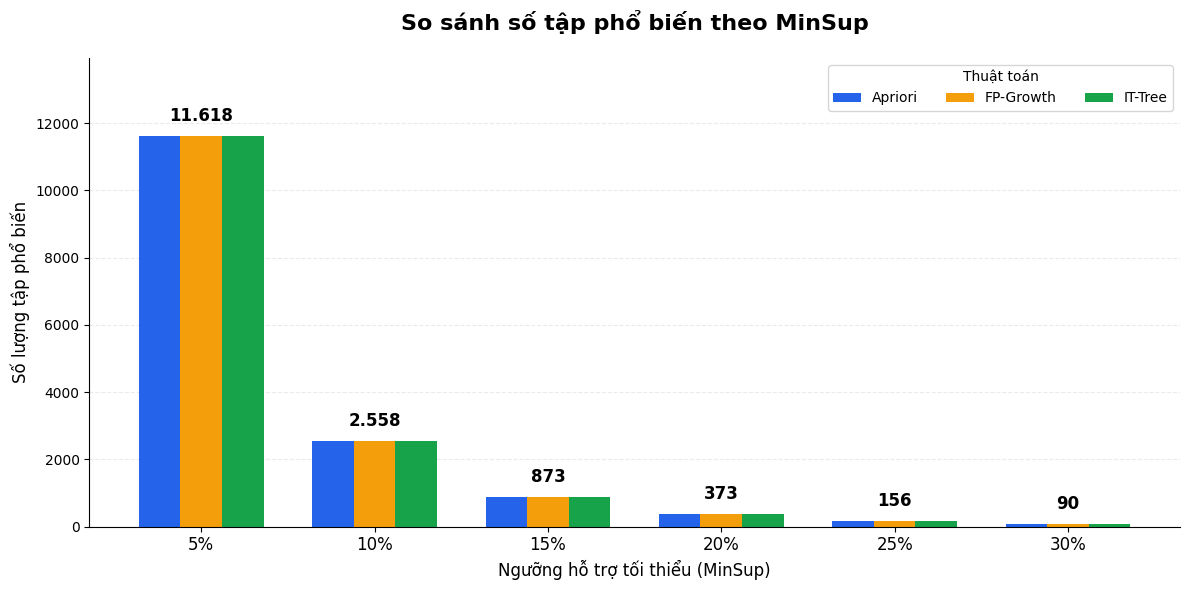

In [ ]:

minsup = experiment_df["MinSup"].values

ap = experiment_df["Apriori_Itemsets"].values
fp = experiment_df["FP_Growth_Itemsets"].values
it = experiment_df["IT_Tree_Itemsets"].values

x = np.arange(len(minsup))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 6))

# Ba thuật toán - ba màu
ax.bar(x - width, ap, width,
       color="#2563EB", label="Apriori")

ax.bar(x, fp, width,
       color="#F59E0B", label="FP-Growth")

ax.bar(x + width, it, width,
       color="#16A34A", label="IT-Tree")

# Chỉ hiển thị một số phía trên mỗi nhóm
for i in range(len(x)):
    value = max(ap[i], fp[i], it[i])

    ax.annotate(
        f"{int(value):,}".replace(",", "."),
        xy=(x[i], value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# Trục X
ax.set_xticks(x)
ax.set_xticklabels([f"{v:.0%}" for v in minsup], fontsize=12)

ax.set_xlabel("Ngưỡng hỗ trợ tối thiểu (MinSup)", fontsize=12)
ax.set_ylabel("Số lượng tập phổ biến", fontsize=12)

ax.set_title(
    "So sánh số tập phổ biến theo MinSup",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Chú giải
ax.legend(title="Thuật toán", loc="upper right", ncol=3)

# Giới hạn trục Y
ax.set_ylim(0, max(max(ap), max(fp), max(it)) * 1.2)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("so_sanh_minsup.png", dpi=300, bbox_inches="tight")
plt.show()

Biểu đồ MinSup và thời gian chạy

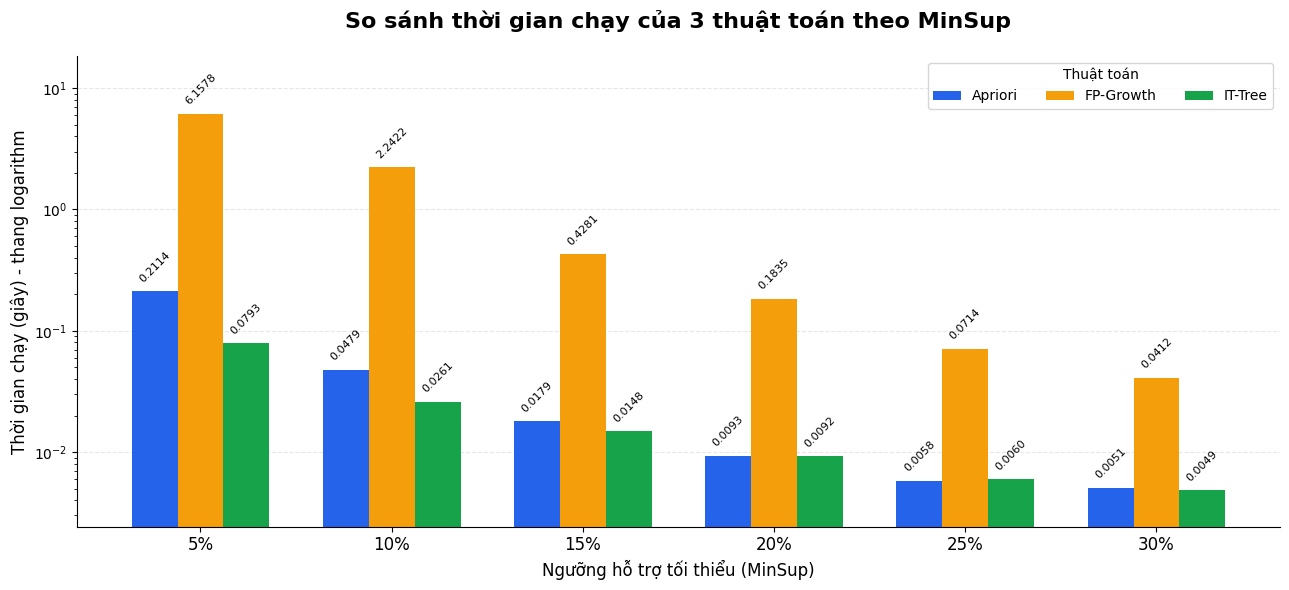

BẢNG THỜI GIAN CHẠY THEO TỪNG MINSUP


,MinSup,Apriori_Time,FP_Growth_Time,IT_Tree_Time
0,0.05,0.2114,6.1578,0.0793
1,0.10,0.0479,2.2422,0.0261
2,0.15,0.0179,0.4281,0.0148
3,0.20,0.0093,0.1835,0.0092
4,0.25,0.0058,0.0714,0.0060
5,0.30,0.0051,0.0412,0.0049


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Lấy dữ liệu
minsup = experiment_df["MinSup"].values
ap = experiment_df["Apriori_Time"].values
fp = experiment_df["FP_Growth_Time"].values
it = experiment_df["IT_Tree_Time"].values

x = np.arange(len(minsup))
width = 0.24

fig, ax = plt.subplots(figsize=(13, 6))

# Vẽ 3 thuật toán
bars1 = ax.bar(
    x - width, ap, width,
    color="#2563EB", label="Apriori"
)

bars2 = ax.bar(
    x, fp, width,
    color="#F59E0B", label="FP-Growth"
)

bars3 = ax.bar(
    x + width, it, width,
    color="#16A34A", label="IT-Tree"
)

# Trục Y logarithm để nhìn rõ cả 3 thuật toán
ax.set_yscale("log")

# Hiển thị thời gian thực tế trên từng cột
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()

        ax.annotate(
            f"{h:.4f}",
            xy=(bar.get_x() + bar.get_width()/2, h),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=45
        )

# Trục X
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{v:.0%}" for v in minsup],
    fontsize=12
)

# Tiêu đề
ax.set_title(
    "So sánh thời gian chạy của 3 thuật toán theo MinSup",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Ngưỡng hỗ trợ tối thiểu (MinSup)", fontsize=12)
ax.set_ylabel("Thời gian chạy (giây) - thang logarithm", fontsize=12)

# Chú giải
ax.legend(
    title="Thuật toán",
    loc="upper right",
    ncol=3
)

# Đường lưới
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Chỉnh giới hạn trục Y
all_times = np.concatenate([ap, fp, it])
ax.set_ylim(
    all_times.min() / 2,
    all_times.max() * 3
)

# Làm gọn
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Lưu biểu đồ
plt.savefig(
    "so_sanh_thoi_gian_minsup.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Bảng thời gian chạy
print("BẢNG THỜI GIAN CHẠY THEO TỪNG MINSUP")

bang_thoi_gian = experiment_df[
    ["MinSup", "Apriori_Time",
     "FP_Growth_Time", "IT_Tree_Time"]
]

display(bang_thoi_gian.round(4))

In [ ]:
# HÀM KHAI PHÁ TẬP PHỔ BIẾN

def mine_itemsets(minsup):

    # Chạy Apriori với ngưỡng MinSup
    frequent_itemsets = apriori(
        df_encoded,
        min_support=minsup,
        use_colnames=True
    )

    return frequent_itemsets


# Kiểm tra hàm
itemsets_demo = mine_itemsets(0.1)

print("MinSup: 0.1")
print("Số tập phổ biến:", len(itemsets_demo))

display(itemsets_demo.head(10))

MinSup: 0.1
Số tập phổ biến: 2558


,support,itemsets
0,0.888,(breakfast_Breakfast_No)
1,0.112,(breakfast_Breakfast_Yes)
2,0.608,(eating_out_Low)
3,0.296,(eating_out_Medium)
4,0.504,(fruit_day_High)
5,0.456,(fruit_day_Medium)
6,0.424,(veggies_day_High)
7,0.112,(veggies_day_Low)
8,0.464,(veggies_day_Medium)
9,0.160,(calories_day_Low)


LƯU FILE KẾT QUẢ TỪNG THUẬT TOÁN VÀ BIỂU ĐỒ TRỰC QUAN

In [ ]:
frequent_itemsets_ap.to_csv("frequent_itemsets_apriori.csv", index=False)
frequent_itemsets_fp.to_csv("frequent_itemsets_fpgrowth.csv", index=False)
frequent_itemsets_it.to_csv("frequent_itemsets_ittree.csv", index=False)
experiment_df.to_csv("minsup_experiment_3_algorithms.csv", index=False)
print("Đã lưu 4 file CSV kết quả.")


Nguồn tham khảo : [mlxtend Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/), [mlxtend FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/).